# UNSW-NB15 IDS: Individual Models + Ensemble

**Fresh-kernel → Run All** notebook.

This pipeline:
- loads the official UNSW-NB15 train/test CSVs
- recreates the exact 19 selected features
- loads the saved Phase-1 tuned models and OOF predictions
- evaluates individual models on training data using OOF predictions
- evaluates individual models on the official test set using their original raw-score thresholds
- performs complementary-error analysis
- builds equal-weight, F1-weighted, and stacking ensembles using OOF data
- selects the ensemble threshold using OOF only with FPR <= 2%
- freezes the ensemble
- evaluates it once on the official test set
- saves a final comparison table

**The official test set is never used for ensemble selection or threshold tuning.**


In [1]:
# 1. Imports and configuration
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

TRAIN_PATH = "UNSW_NB15_training-set.csv"
TEST_PATH = "UNSW_NB15_testing-set.csv"
ARTIFACT_DIR = "phase1_artifacts"
ENSEMBLE_DIR = "ensemble_artifacts"
os.makedirs(ENSEMBLE_DIR, exist_ok=True)

MODEL_NAMES = ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "SVM"]

SELECTED_FEATURES = [
    "ct_dst_src_ltm", "sttl", "sbytes", "smean", "dmean", "dttl",
    "dbytes", "ct_state_ttl", "service_none", "ct_dst_sport_ltm",
    "dload", "proto_udp", "sloss", "state_int", "proto_tcp",
    "service_http", "tcprtt", "swin", "response_body_len"
]

INDIVIDUAL_THRESHOLDS = {
    "Random Forest": 0.715,
    "XGBoost": 0.665,
    "LightGBM": 0.650,
    "CatBoost": 0.660,
    "SVM": 0.410
}

print("Configuration loaded.")


Configuration loaded.


In [2]:
# 2. Load the official UNSW-NB15 train/test data
if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(f"Missing: {TRAIN_PATH}")
if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(f"Missing: {TEST_PATH}")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training:", train_df.shape)
print("Testing :", test_df.shape)


Training: (175341, 45)
Testing : (82332, 45)


In [3]:
# 3. Exact Phase-1 preprocessing
TARGET = "label"

def prepare_dataframe(df):
    df = df.copy()
    df = df.drop(columns=["id", "attack_cat"], errors="ignore")

    cat_cols = [c for c in ["proto", "service", "state"] if c in df.columns]
    for col in cat_cols:
        df[col] = (
            df[col].astype(str).str.strip().str.lower().replace("-", "none")
        )

    X = pd.get_dummies(
        df.drop(columns=[TARGET]),
        columns=cat_cols,
        drop_first=False
    )
    y = df[TARGET].astype(int)
    return X, y

X_train_all, y_train = prepare_dataframe(train_df)
X_test_all, y_test = prepare_dataframe(test_df)

X_test_all = X_test_all.reindex(columns=X_train_all.columns, fill_value=0)

missing_train = [c for c in SELECTED_FEATURES if c not in X_train_all.columns]
missing_test = [c for c in SELECTED_FEATURES if c not in X_test_all.columns]
if missing_train or missing_test:
    raise ValueError(f"Missing features. train={missing_train}, test={missing_test}")

X_selected = X_train_all[SELECTED_FEATURES].copy()
X_test_selected = X_test_all[SELECTED_FEATURES].copy()

print("X_selected:", X_selected.shape)
print("X_test_selected:", X_test_selected.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_selected: (175341, 19)
X_test_selected: (82332, 19)
y_train: (175341,)
y_test: (82332,)


In [4]:
# 4. Load Phase-1 models and OOF artifacts
def load_joblib(filename, required=True):
    path = os.path.join(ARTIFACT_DIR, filename)
    if not os.path.exists(path):
        if required:
            raise FileNotFoundError(f"Missing artifact: {path}")
        return None
    return joblib.load(path)

tuned_models = load_joblib("tuned_models.joblib", required=True)
oof_scores = load_joblib("oof_scores.joblib", required=True)

# Optional artifacts are loaded and checked when present.
saved_y_train = load_joblib("y_train.joblib", required=False)
saved_y_test = load_joblib("y_test.joblib", required=False)
saved_features = load_joblib("selected_features.joblib", required=False)

if saved_y_train is not None:
    if not np.array_equal(np.asarray(saved_y_train), np.asarray(y_train)):
        raise ValueError("Saved y_train does not match the official training CSV.")

if saved_y_test is not None:
    if not np.array_equal(np.asarray(saved_y_test), np.asarray(y_test)):
        raise ValueError("Saved y_test does not match the official testing CSV.")

if saved_features is not None and list(saved_features) != SELECTED_FEATURES:
    raise ValueError("Saved selected feature list differs from the Phase-1 list.")

for name in MODEL_NAMES:
    if name not in tuned_models:
        raise ValueError(f"Missing tuned model: {name}")
    if name not in oof_scores:
        raise ValueError(f"Missing OOF scores: {name}")
    if len(oof_scores[name]) != len(y_train):
        raise ValueError(f"OOF length mismatch for {name}.")

print("Loaded models:", list(tuned_models.keys()))
print("Loaded OOF models:", list(oof_scores.keys()))


Loaded models: ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'SVM']
Loaded OOF models: ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'SVM']


In [5]:
# 5. Score helper
def get_score(model, X):
    if hasattr(model, "predict_proba"):
        return np.asarray(model.predict_proba(X))[:, 1]
    if hasattr(model, "decision_function"):
        return np.asarray(model.decision_function(X)).ravel()
    return np.asarray(model.predict(X)).ravel()

print("get_score() ready.")


get_score() ready.


In [6]:
# 6. Common metric function
def metrics_from_scores(y_true, scores, threshold):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).ravel()
    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "FPR": fp / (fp + tn) if (fp + tn) else 0.0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }


In [7]:
# 7. Individual-model TRAINING evaluation using OOF predictions
train_rows = []

for name in MODEL_NAMES:
    m = metrics_from_scores(
        y_train,
        oof_scores[name],
        INDIVIDUAL_THRESHOLDS[name]
    )
    train_rows.append({
        "Model": name,
        "Dataset": "Training (OOF)",
        "Threshold": INDIVIDUAL_THRESHOLDS[name],
        **m
    })

train_results_df = pd.DataFrame(train_rows)

display(train_results_df[
    ["Model","Dataset","Threshold","Accuracy","Precision","Recall",
     "F1","ROC-AUC","FPR","TN","FP","FN","TP"]
].sort_values("F1", ascending=False).reset_index(drop=True))


,Model,Dataset,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,TN,FP,FN,TP
0,LightGBM,Training (OOF),0.650,0.939780,0.989947,0.920874,0.954162,0.993728,0.019929,54884,1116,9443,109898
1,Random Forest,Training (OOF),0.715,0.938103,0.990151,0.918192,0.952815,0.993471,0.019464,54910,1090,9763,109578
2,XGBoost,Training (OOF),0.665,0.937995,0.990016,0.918159,0.952735,0.993408,0.019732,54895,1105,9767,109574
3,CatBoost,Training (OOF),0.660,0.936700,0.989907,0.916341,0.951704,0.993319,0.019911,54885,1115,9984,109357
4,SVM,Training (OOF),0.410,0.852510,0.988524,0.792502,0.879726,0.976806,0.019607,54902,1098,24763,94578


In [8]:
# 8. Individual-model OFFICIAL TEST evaluation
# IMPORTANT: raw model scores + original frozen thresholds.
test_raw_scores = {}
test_rows = []

for name in MODEL_NAMES:
    scores = get_score(tuned_models[name], X_test_selected)
    test_raw_scores[name] = scores

    m = metrics_from_scores(
        y_test,
        scores,
        INDIVIDUAL_THRESHOLDS[name]
    )

    test_rows.append({
        "Model": name,
        "Dataset": "Official Test",
        "Threshold": INDIVIDUAL_THRESHOLDS[name],
        **m
    })

test_results_df = pd.DataFrame(test_rows)

print("INDIVIDUAL OFFICIAL-TEST RESULTS")
display(test_results_df[
    ["Model","Dataset","Threshold","Accuracy","Precision","Recall",
     "F1","ROC-AUC","FPR","TN","FP","FN","TP"]
].sort_values("F1", ascending=False).reset_index(drop=True))


INDIVIDUAL OFFICIAL-TEST RESULTS


,Model,Dataset,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,TN,FP,FN,TP
0,CatBoost,Official Test,0.660,0.941311,0.942468,0.951491,0.946958,0.989232,0.071162,34367,2633,2199,43133
1,LightGBM,Official Test,0.650,0.936987,0.938656,0.947476,0.943045,0.988339,0.075865,34193,2807,2381,42951
2,XGBoost,Official Test,0.665,0.936209,0.938263,0.946418,0.942322,0.987559,0.076297,34177,2823,2429,42903
3,Random Forest,Official Test,0.715,0.935359,0.938552,0.944432,0.941483,0.987130,0.075757,34197,2803,2519,42813
4,SVM,Official Test,0.410,0.875249,0.952155,0.814347,0.877876,0.957738,0.050135,35145,1855,8416,36916


In [9]:
# 9. Benchmark sanity check
# Previously established official-test F1 values from the Phase-1 experiment.
KNOWN_F1 = {
    "CatBoost": 0.9470,
    "LightGBM": 0.9430,
    "XGBoost": 0.9423,
    "Random Forest": 0.9415,
    "SVM": 0.8779
}

check = test_results_df[["Model","F1"]].copy()
check["Previously_Established_F1"] = check["Model"].map(KNOWN_F1)
check["Difference"] = check["F1"] - check["Previously_Established_F1"]

display(check.sort_values("Model").reset_index(drop=True))

if check["Difference"].abs().max() > 0.003:
    raise RuntimeError(
        "Individual official-test F1 does not reproduce the established "
        "Phase-1 benchmark. Stop here and inspect preprocessing/model artifacts "
        "before trusting any ensemble result."
    )

print("Individual test benchmark reproduced within tolerance.")


,Model,F1,Previously_Established_F1,Difference
0,CatBoost,0.946958,0.9470,-0.000042
1,LightGBM,0.943045,0.9430,0.000045
2,Random Forest,0.941483,0.9415,-0.000017
3,SVM,0.877876,0.8779,-0.000024
4,XGBoost,0.942322,0.9423,0.000022


Individual test benchmark reproduced within tolerance.


In [10]:
# 10. Rank-normalize OOF scores for ensemble construction
def percentile_rank_transform(reference_scores, scores):
    reference_scores = np.asarray(reference_scores).ravel()
    scores = np.asarray(scores).ravel()
    sorted_ref = np.sort(reference_scores)
    ranks = np.searchsorted(sorted_ref, scores, side="right")
    return ranks / len(sorted_ref)

oof_rank = {
    name: percentile_rank_transform(oof_scores[name], oof_scores[name])
    for name in MODEL_NAMES
}

print("OOF rank normalization complete.")


OOF rank normalization complete.


In [11]:
# 11. Complementary-error analysis
error_masks = {}

for name in MODEL_NAMES:
    pred = (
        np.asarray(oof_scores[name]) >= INDIVIDUAL_THRESHOLDS[name]
    ).astype(int)
    error_masks[name] = pred != np.asarray(y_train)

error_rate_df = pd.DataFrame({
    name: [error_masks[name].mean()]
    for name in MODEL_NAMES
}, index=["OOF Error Rate"]).T

print("OOF error rates")
display(error_rate_df)

jaccard = pd.DataFrame(index=MODEL_NAMES, columns=MODEL_NAMES, dtype=float)
for a in MODEL_NAMES:
    for b in MODEL_NAMES:
        A, B = error_masks[a], error_masks[b]
        union = np.logical_or(A, B).sum()
        inter = np.logical_and(A, B).sum()
        jaccard.loc[a,b] = inter / union if union else 0

print("Jaccard similarity of error sets")
display(jaccard)

recovery = pd.DataFrame(index=MODEL_NAMES, columns=MODEL_NAMES, dtype=float)
for a in MODEL_NAMES:
    for b in MODEL_NAMES:
        denom = error_masks[a].sum()
        recovery.loc[a,b] = (
            np.logical_and(error_masks[a], ~error_masks[b]).sum() / denom
            if denom else 0
        )

print("Fraction of model-A errors recovered by model-B")
display(recovery)


OOF error rates


,OOF Error Rate
Random Forest,0.061897
XGBoost,0.062005
LightGBM,0.060220
CatBoost,0.063300
SVM,0.147490


Jaccard similarity of error sets


,Random Forest,XGBoost,LightGBM,CatBoost,SVM
Random Forest,1.000000,0.759109,0.763756,0.744576,0.302377
XGBoost,0.759109,1.000000,0.801984,0.783940,0.307876
LightGBM,0.763756,0.801984,1.000000,0.806188,0.299925
CatBoost,0.744576,0.783940,0.806188,1.000000,0.323450
SVM,0.302377,0.307876,0.299925,0.323450,1.000000


Fraction of model-A errors recovered by model-B


,Random Forest,XGBoost,LightGBM,CatBoost,SVM
Random Forest,0.000000,0.136184,0.145674,0.136736,0.214595
XGBoost,0.137693,0.000000,0.122701,0.111939,0.204654
LightGBM,0.121887,0.096695,0.000000,0.084478,0.204186
CatBoost,0.155870,0.130102,0.129021,0.000000,0.186143
SVM,0.670392,0.665636,0.675071,0.650710,0.000000


In [12]:
# 12. Candidate ensembles using OOF predictions
oof_matrix = np.column_stack([oof_rank[name] for name in MODEL_NAMES])

equal_score = oof_matrix.mean(axis=1)

f1_weights_raw = np.array([
    f1_score(
        y_train,
        (np.asarray(oof_scores[name]) >= INDIVIDUAL_THRESHOLDS[name]).astype(int),
        zero_division=0
    )
    for name in MODEL_NAMES
])
f1_weights = f1_weights_raw / f1_weights_raw.sum()
weighted_score = oof_matrix @ f1_weights

stacker = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)
stacker.fit(oof_matrix, y_train)
stack_score = stacker.predict_proba(oof_matrix)[:,1]

ensemble_oof_scores = {
    "Equal-Weight": equal_score,
    "F1-Weighted": weighted_score,
    "Stacking": stack_score
}

print("F1-derived ensemble weights:")
for name, w in zip(MODEL_NAMES, f1_weights):
    print(f"{name:15s}: {w:.4f}")


F1-derived ensemble weights:
Random Forest  : 0.2031
XGBoost        : 0.2031
LightGBM       : 0.2034
CatBoost       : 0.2029
SVM            : 0.1875


In [13]:
# 13. OOF threshold optimization: FPR <= 2%
def find_threshold(y_true, scores, max_fpr=0.02):
    scores = np.asarray(scores).ravel()
    candidates = np.unique(
        np.quantile(scores, np.linspace(0.001, 0.999, 999))
    )

    best = None
    for threshold in candidates:
        m = metrics_from_scores(y_true, scores, threshold)
        if m["FPR"] <= max_fpr:
            key = (m["F1"], m["Recall"])
            if best is None or key > best["key"]:
                best = {"threshold": float(threshold), "metrics": m, "key": key}

    if best is None:
        raise RuntimeError("No threshold satisfied FPR <= 2%.")

    return best

ensemble_selection = {}
rows = []

for name, scores in ensemble_oof_scores.items():
    sel = find_threshold(y_train, scores, max_fpr=0.02)
    ensemble_selection[name] = sel
    m = sel["metrics"]
    rows.append({
        "Ensemble": name,
        "OOF Threshold": sel["threshold"],
        "OOF Accuracy": m["Accuracy"],
        "OOF Precision": m["Precision"],
        "OOF Recall": m["Recall"],
        "OOF F1": m["F1"],
        "OOF ROC-AUC": m["ROC-AUC"],
        "OOF FPR": m["FPR"]
    })

ensemble_oof_df = pd.DataFrame(rows)
display(ensemble_oof_df.sort_values(
    ["OOF F1","OOF Recall"], ascending=False
).reset_index(drop=True))


,Ensemble,OOF Threshold,OOF Accuracy,OOF Precision,OOF Recall,OOF F1,OOF ROC-AUC,OOF FPR
0,Stacking,0.681141,0.940014,0.990233,0.920949,0.954335,0.993823,0.019357
1,F1-Weighted,0.381385,0.928727,0.989831,0.904576,0.945285,0.992827,0.019804
2,Equal-Weight,0.383378,0.926999,0.990019,0.901836,0.943872,0.992716,0.019375


In [14]:
# 14. Freeze the ensemble
eligible = ensemble_oof_df[ensemble_oof_df["OOF FPR"] <= 0.02].copy()
if eligible.empty:
    raise RuntimeError("No ensemble candidate satisfies OOF FPR <= 2%.")

best_ensemble_name = (
    eligible.sort_values(["OOF F1","OOF Recall"], ascending=False)
    .iloc[0]["Ensemble"]
)
best_ensemble_threshold = ensemble_selection[best_ensemble_name]["threshold"]

print("FROZEN ENSEMBLE:", best_ensemble_name)
print("FROZEN THRESHOLD:", best_ensemble_threshold)

joblib.dump(
    {
        "ensemble_name": best_ensemble_name,
        "threshold": best_ensemble_threshold,
        "model_names": MODEL_NAMES,
        "individual_thresholds": INDIVIDUAL_THRESHOLDS,
        "f1_weights": dict(zip(MODEL_NAMES, f1_weights))
    },
    os.path.join(ENSEMBLE_DIR, "ensemble_selection.joblib")
)


FROZEN ENSEMBLE: Stacking
FROZEN THRESHOLD: 0.6811411239055203


['ensemble_artifacts\\ensemble_selection.joblib']

In [15]:
# 15. Apply frozen ensemble to official test data
# Test rank normalization uses ONLY the OOF/training score distribution.
test_rank = {
    name: percentile_rank_transform(oof_scores[name], test_raw_scores[name])
    for name in MODEL_NAMES
}
test_rank_matrix = np.column_stack([test_rank[name] for name in MODEL_NAMES])

if best_ensemble_name == "Equal-Weight":
    ensemble_test_score = test_rank_matrix.mean(axis=1)
elif best_ensemble_name == "F1-Weighted":
    ensemble_test_score = test_rank_matrix @ f1_weights
elif best_ensemble_name == "Stacking":
    ensemble_test_score = stacker.predict_proba(test_rank_matrix)[:,1]
else:
    raise ValueError(best_ensemble_name)

ensemble_test_metrics = metrics_from_scores(
    y_test, ensemble_test_score, best_ensemble_threshold
)

print("FINAL ENSEMBLE OFFICIAL-TEST RESULT")
display(pd.DataFrame([{
    "Model": f"ENSEMBLE ({best_ensemble_name})",
    "Dataset": "Official Test",
    "Threshold": best_ensemble_threshold,
    **ensemble_test_metrics
}]))


FINAL ENSEMBLE OFFICIAL-TEST RESULT


,Model,Dataset,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,TN,FP,FN,TP
0,ENSEMBLE (Stacking),Official Test,0.681141,0.938481,0.940163,0.948646,0.944385,0.988781,0.073973,34263,2737,2328,43004


In [16]:
# 16. Final comparison: all individual models + ensemble
ensemble_train_metrics = ensemble_selection[best_ensemble_name]["metrics"]

all_rows = []

for _, r in train_results_df.iterrows():
    all_rows.append(r.to_dict())

for _, r in test_results_df.iterrows():
    all_rows.append(r.to_dict())

all_rows.append({
    "Model": f"ENSEMBLE ({best_ensemble_name})",
    "Dataset": "Training (OOF)",
    "Threshold": best_ensemble_threshold,
    **ensemble_train_metrics
})

all_rows.append({
    "Model": f"ENSEMBLE ({best_ensemble_name})",
    "Dataset": "Official Test",
    "Threshold": best_ensemble_threshold,
    **ensemble_test_metrics
})

final_comparison = pd.DataFrame(all_rows)

cols = [
    "Model","Dataset","Threshold","Accuracy","Precision","Recall",
    "F1","ROC-AUC","FPR","TN","FP","FN","TP"
]
final_comparison = final_comparison[cols]

print("FINAL COMPARISON")
display(final_comparison.sort_values(
    ["Dataset","F1"], ascending=[True,False]
).reset_index(drop=True))

final_comparison.to_csv(
    os.path.join(ENSEMBLE_DIR, "final_model_comparison.csv"),
    index=False
)


FINAL COMPARISON


,Model,Dataset,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,TN,FP,FN,TP
0,CatBoost,Official Test,0.660000,0.941311,0.942468,0.951491,0.946958,0.989232,0.071162,34367,2633,2199,43133
1,ENSEMBLE (Stacking),Official Test,0.681141,0.938481,0.940163,0.948646,0.944385,0.988781,0.073973,34263,2737,2328,43004
2,LightGBM,Official Test,0.650000,0.936987,0.938656,0.947476,0.943045,0.988339,0.075865,34193,2807,2381,42951
3,XGBoost,Official Test,0.665000,0.936209,0.938263,0.946418,0.942322,0.987559,0.076297,34177,2823,2429,42903
4,Random Forest,Official Test,0.715000,0.935359,0.938552,0.944432,0.941483,0.987130,0.075757,34197,2803,2519,42813
5,SVM,Official Test,0.410000,0.875249,0.952155,0.814347,0.877876,0.957738,0.050135,35145,1855,8416,36916
6,ENSEMBLE (Stacking),Training (OOF),0.681141,0.940014,0.990233,0.920949,0.954335,0.993823,0.019357,54916,1084,9434,109907
7,LightGBM,Training (OOF),0.650000,0.939780,0.989947,0.920874,0.954162,0.993728,0.019929,54884,1116,9443,109898
8,Random Forest,Training (OOF),0.715000,0.938103,0.990151,0.918192,0.952815,0.993471,0.019464,54910,1090,9763,109578
9,XGBoost,Training (OOF),0.665000,0.937995,0.990016,0.918159,0.952735,0.993408,0.019732,54895,1105,9767,109574


In [17]:
# 17. Train-vs-test shift
train_part = final_comparison[
    final_comparison["Dataset"] == "Training (OOF)"
][["Model","Accuracy","Precision","Recall","F1","ROC-AUC","FPR"]]

test_part = final_comparison[
    final_comparison["Dataset"] == "Official Test"
][["Model","Accuracy","Precision","Recall","F1","ROC-AUC","FPR"]]

shift = train_part.merge(
    test_part, on="Model", suffixes=("_TrainOOF","_Test")
)

for metric in ["Accuracy","Precision","Recall","F1","ROC-AUC","FPR"]:
    shift[f"{metric}_TestMinusTrain"] = (
        shift[f"{metric}_Test"] - shift[f"{metric}_TrainOOF"]
    )

display(shift)


,Model,Accuracy_TrainOOF,Precision_TrainOOF,Recall_TrainOOF,F1_TrainOOF,ROC-AUC_TrainOOF,FPR_TrainOOF,Accuracy_Test,Precision_Test,Recall_Test,F1_Test,ROC-AUC_Test,FPR_Test,Accuracy_TestMinusTrain,Precision_TestMinusTrain,Recall_TestMinusTrain,F1_TestMinusTrain,ROC-AUC_TestMinusTrain,FPR_TestMinusTrain
0,Random Forest,0.938103,0.990151,0.918192,0.952815,0.993471,0.019464,0.935359,0.938552,0.944432,0.941483,0.987130,0.075757,-0.002744,-0.051598,0.026240,-0.011332,-0.006342,0.056292
1,XGBoost,0.937995,0.990016,0.918159,0.952735,0.993408,0.019732,0.936209,0.938263,0.946418,0.942322,0.987559,0.076297,-0.001786,-0.051753,0.028259,-0.010412,-0.005849,0.056565
2,LightGBM,0.939780,0.989947,0.920874,0.954162,0.993728,0.019929,0.936987,0.938656,0.947476,0.943045,0.988339,0.075865,-0.002793,-0.051292,0.026603,-0.011117,-0.005390,0.055936
3,CatBoost,0.936700,0.989907,0.916341,0.951704,0.993319,0.019911,0.941311,0.942468,0.951491,0.946958,0.989232,0.071162,0.004610,-0.047439,0.035151,-0.004746,-0.004087,0.051251
4,SVM,0.852510,0.988524,0.792502,0.879726,0.976806,0.019607,0.875249,0.952155,0.814347,0.877876,0.957738,0.050135,0.022739,-0.036369,0.021845,-0.001850,-0.019069,0.030528
5,ENSEMBLE (Stacking),0.940014,0.990233,0.920949,0.954335,0.993823,0.019357,0.938481,0.940163,0.948646,0.944385,0.988781,0.073973,-0.001533,-0.050070,0.027696,-0.009950,-0.005042,0.054616


Frozen ensemble confusion matrix:


,Predicted 0,Predicted 1
Actual 0,34263,2737
Actual 1,2328,43004


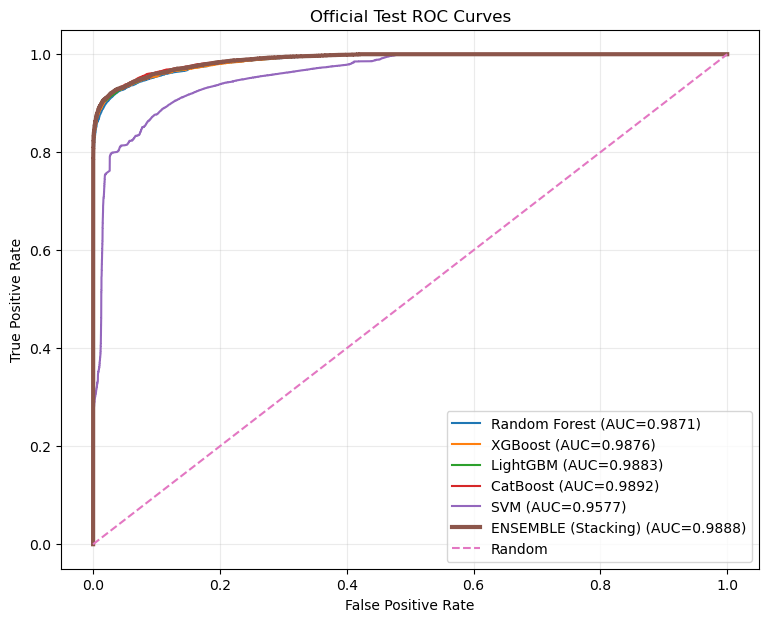

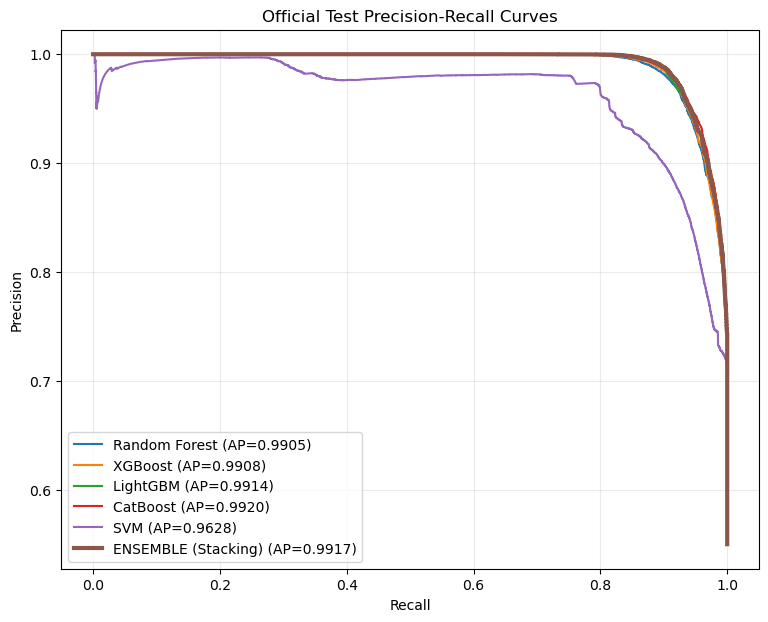

In [18]:
# 18. Final plots
ensemble_pred_test = (
    ensemble_test_score >= best_ensemble_threshold
).astype(int)

cm = confusion_matrix(y_test, ensemble_pred_test, labels=[0,1])
print("Frozen ensemble confusion matrix:")
display(pd.DataFrame(
    cm,
    index=["Actual 0","Actual 1"],
    columns=["Predicted 0","Predicted 1"]
))

plt.figure(figsize=(9,7))
for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, test_raw_scores[name])
    auc = roc_auc_score(y_test, test_raw_scores[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

fpr, tpr, _ = roc_curve(y_test, ensemble_test_score)
auc = roc_auc_score(y_test, ensemble_test_score)
plt.plot(fpr, tpr, linewidth=3,
         label=f"ENSEMBLE ({best_ensemble_name}) (AUC={auc:.4f})")
plt.plot([0,1],[0,1], linestyle="--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Official Test ROC Curves")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(9,7))
for name in MODEL_NAMES:
    precision, recall, _ = precision_recall_curve(y_test, test_raw_scores[name])
    ap = average_precision_score(y_test, test_raw_scores[name])
    plt.plot(recall, precision, label=f"{name} (AP={ap:.4f})")

precision, recall, _ = precision_recall_curve(y_test, ensemble_test_score)
ap = average_precision_score(y_test, ensemble_test_score)
plt.plot(recall, precision, linewidth=3,
         label=f"ENSEMBLE ({best_ensemble_name}) (AP={ap:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Official Test Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [19]:
# 19. Save final metadata
final_metadata = {
    "ensemble_name": best_ensemble_name,
    "ensemble_threshold": float(best_ensemble_threshold),
    "individual_thresholds": INDIVIDUAL_THRESHOLDS,
    "model_names": MODEL_NAMES,
    "f1_weights": dict(zip(MODEL_NAMES, f1_weights)),
    "individual_train_oof": train_results_df,
    "individual_official_test": test_results_df,
    "ensemble_oof": ensemble_oof_df,
    "final_comparison": final_comparison,
    "ensemble_official_test_metrics": ensemble_test_metrics
}

joblib.dump(
    final_metadata,
    os.path.join(ENSEMBLE_DIR, "final_ensemble_metadata.joblib")
)

print("Saved:")
print(os.path.join(ENSEMBLE_DIR, "ensemble_selection.joblib"))
print(os.path.join(ENSEMBLE_DIR, "final_ensemble_metadata.joblib"))
print(os.path.join(ENSEMBLE_DIR, "final_model_comparison.csv"))


Saved:
ensemble_artifacts\ensemble_selection.joblib
ensemble_artifacts\final_ensemble_metadata.joblib
ensemble_artifacts\final_model_comparison.csv
